# 02 · Is it learning? Samples, loss curves, instability and mode collapse

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/gan_Mnist/blob/main/notebooks/02_training_instability_and_mode_collapse.ipynb)

**After this notebook you will be able to** follow a GAN through training with samples and loss curves, measure what the loss cannot tell you,
and recognise (and count) *mode collapse* and instability on a toy problem where we can see everything.

*Time: about 50 minutes (the training cells take roughly ten minutes on a laptop CPU in total). Prerequisite: notebook 01.*

## 1 · The big question

In a normal classifier, "is it learning?" has a simple answer: the loss goes down and the accuracy goes up.
In a GAN, **both networks are changing at the same time**, so the loss of one is the opponent's success. What should we watch?

Today we look at three things, and we will find that they do not always agree:

1. **Samples** across training: the most direct, but subjective.
2. **Loss curves**: objective, but hard to interpret.
3. **A measuring device**: a digit classifier that tells us how *recognisable* and how *varied* the generated digits are.

Then we study two classic ways in which GAN training goes wrong:

- **Instability:** the game does not settle; the generator keeps changing without improving.
- **Mode collapse:** the generator produces only a few of the kinds of pictures that exist in the real data (for instance only a few of the ten digits).

## 2 · Intuition first: the forger who found a loophole

Remember the forger and the detective. Suppose the detective happens to believe every "7" the forger shows him. The forger is rewarded for fooling the detective, *not for variety*,
so the easiest strategy is to paint **only 7s**. Then the detective learns that 7s are suspicious, and the forger switches to painting only 1s ... and so on: a game of whack-a-mole.
Nothing in the rules asks him to paint all ten digits. This is the usual explanation of **mode collapse** ("mode" = one kind of picture in the real data).
(It is an intuition; real cases are messier, which is why we measure.)

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/gan_Mnist.git"], check=True)
    os.chdir("gan_Mnist/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import gan as gn
from src.gan import save_figure

gn.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

## 3 · A measuring device

To count how many different digits a GAN makes, we need something that can recognise digits. We train a small classifier on the real MNIST labels
(2 epochs, a few seconds) and use it as a **ruler**: for a batch of generated pictures it tells us (a) *how confident* it is on average and (b) *which digits it thinks it sees*.
It is a crude ruler, since a classifier can be confident about a picture that is not a digit at all, and we will say so where it matters.
(The same idea, with a much bigger classifier, is behind the Inception Score of Salimans et al., 2016.)

In [2]:
(x_train, y_train), (x_test, y_test) = gn.load_mnist_with_labels()

gn.set_seed()
classifier = gn.build_classifier()
classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
classifier.fit(x_train, y_train, epochs=2, batch_size=128, verbose=0)
print("the ruler: accuracy on the 10,000 real test digits:", round(classifier.evaluate(x_test, y_test, verbose=0)[1], 4))

confidence, counts = gn.class_statistics(classifier, x_test[:2000])
print(f"on 2,000 real digits: average confidence {confidence:.3f}, pictures per predicted digit: {counts.tolist()}")

the ruler: accuracy on the 10,000 real test digits: 0.9796


on 2,000 real digits: average confidence 0.964, pictures per predicted digit: [178, 236, 224, 205, 216, 188, 176, 201, 181, 195]


**What to notice.** On real digits the ruler is right almost every time, its average confidence is very high and all ten digits appear in about equal numbers.
That is the target a good GAN should come close to: **confident and varied**.

## 4 · Following the digit GAN for 5,000 steps

Same networks and settings as notebook 01 (32 filters, batches of 64, seed 42), but trained **longer: 5,000 steps (about five passes over the data)**,
with a snapshot of the generator's output for the same 256 noise vectors at seven moments. (The original script ran 100 epochs; a CPU cannot do that here.)

In [3]:
STEPS = 5000
moments = (0, 500, 1000, 2000, 3000, 4000, 5000)
fixed_noise = np.random.default_rng(0).standard_normal((256, gn.NOISE_DIM)).astype("float32")

gn.set_seed()
generator, discriminator = gn.build_generator(width=32), gn.build_discriminator(width=32)
start = time.time()
history, snapshots = gn.train_gan(generator, discriminator, x_train, steps=STEPS, batch_size=64,
                                  snapshot_steps=moments, fixed_noise=fixed_noise)
print(f"trained for {STEPS} steps in {time.time() - start:.0f} s")

trained for 5000 steps in 485 s


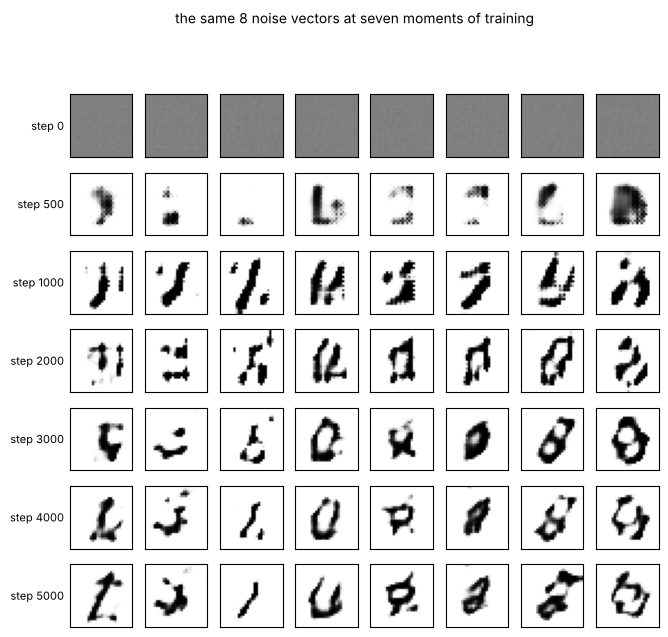

In [4]:
fig = gn.plot_progress(snapshots, columns=8)
fig.suptitle("the same 8 noise vectors at seven moments of training", y=1.0, fontsize=10)
save_figure(fig, "02_samples_across_training.png")
plt.show()

**What to notice.** Same eight noise vectors, seven moments:

- **Step 0:** uniform grey. **Step 500:** blobs and short strokes.
- **Step 1000:** thick strokes, and several pictures look alike (a slanted stroke): little variety yet.
- **Step 2000:** more varied and more detailed shapes.
- **Step 3000:** closed loops appear (in columns 4, 6, 7 and 8).
- **Steps 4000 and 5000:** the pictures keep changing. At step 5000 a few resemble digits (column 3 is a thin 1, columns 4 and 8 something like a 0), but most are still not clean digits, and for several noise vectors the picture is almost the same at steps 4000 and 5000.

After about five passes over the data the forger makes digit-like scribbles. We will not call them good digits.

*Figure: the generator's output for the same eight noise vectors at steps 0, 500, 1000, 2000, 3000, 4000 and 5000.*

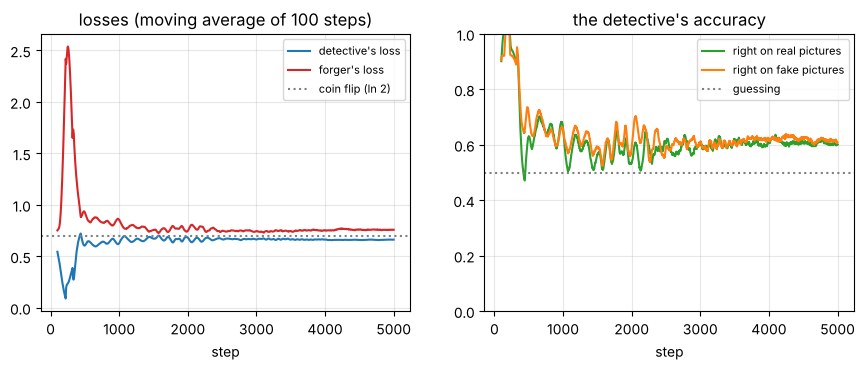

d_loss      average over steps 1-500: 0.452   steps 2501-3000: 0.667   steps 4501-5000: 0.661
g_loss      average over steps 1-500: 1.344   steps 2501-3000: 0.747   steps 4501-5000: 0.758
d_acc_real  average over steps 1-500: 0.800   steps 2501-3000: 0.587   steps 4501-5000: 0.605
d_acc_fake  average over steps 1-500: 0.840   steps 2501-3000: 0.606   steps 4501-5000: 0.615


In [5]:
fig = gn.plot_curves(history, window=100)
save_figure(fig, "02_loss_curves.png")
plt.show()
for name in ["d_loss", "g_loss", "d_acc_real", "d_acc_fake"]:
    values = np.array(history[name])
    print(f"{name:11s} average over steps 1-500: {values[:500].mean():.3f}   steps 2501-3000: {values[2500:3000].mean():.3f}   steps 4501-5000: {values[-500:].mean():.3f}")

**What to notice** (the printed averages and the figure):

- **First 500 steps:** the detective wins easily (right on 80% of the real and 84% of the fake pictures, loss 0.452), and the forger's loss is high (1.344 on average; the curve peaks around 2.5 near step 250).
- **Until about step 2,500** both curves wobble as the two networks take turns being ahead.
- **After that the curves are almost flat:** the detective's loss is 0.667 and 0.661, close to the coin-flip value 0.693; his accuracy is about 60% on both kinds of pictures; the forger's loss is about 0.75.
- Yet **the pictures keep changing** between step 3,000 and step 5,000 (loops turn into other shapes). A flat loss curve does *not* mean that training has finished or that the pictures are good.

*Figure: losses (left) and the detective's accuracy (right) over 5,000 steps, smoothed with a moving average of 100 steps.*

### Check yourself

1. The detective's loss stays near 0.69 for thousands of steps. Does that prove the forger's pictures are good?
2. Why is the *ruler* (classifier) not a perfect judge of the pictures?

<details>
<summary>Answers</summary>


1. No. 0.69 only says the detective cannot do better than guessing. That happens when the forger is excellent, but also when the detective is too weak or the forger found a loophole (notebook 01 showed a draw with a wrong spread).
2. It was trained on real digits only. It can be confident about a picture that is not a proper digit, and it only says which of the ten classes is most likely, not whether the stroke quality is good.

</details>

## 5 · Measuring with the ruler

For each snapshot we ask the ruler about the 256 generated pictures: how confident is it on average, and how many of the ten digits does it see (we count a digit as *present* if it gets at least 3% of the pictures, i.e. 8 of 256)?

 step confidence digits present   pictures per predicted digit 0..9
    0      0.542              1   [0, 0, 0, 0, 0, 0, 0, 0, 256, 0]
  500      0.663              7   [18, 13, 28, 28, 2, 60, 6, 52, 3, 46]


 1000      0.812              7   [1, 77, 28, 7, 70, 8, 10, 45, 8, 2]
 2000      0.752             10   [15, 17, 43, 19, 41, 26, 9, 45, 28, 13]
 3000      0.731              9   [20, 10, 35, 46, 2, 25, 21, 22, 19, 56]
 4000      0.736              8   [31, 18, 22, 49, 7, 17, 6, 21, 17, 68]


 5000      0.747             10   [20, 21, 29, 29, 12, 27, 16, 18, 27, 57]


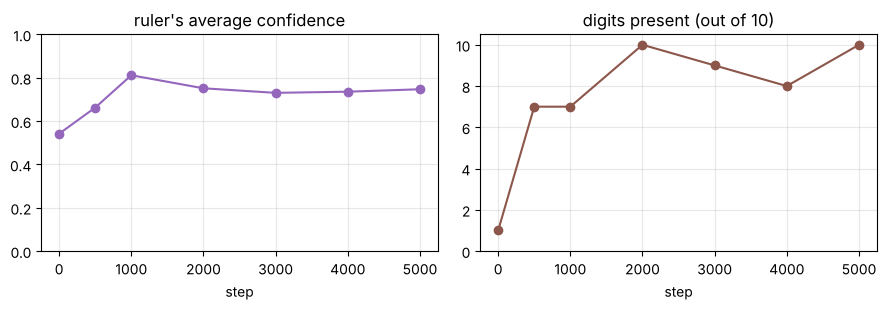

In [6]:
rows = []
print(f"{'step':>5s} {'confidence':>10s} {'digits present':>14s}   pictures per predicted digit 0..9")
for step_number in moments:
    confidence, counts = gn.class_statistics(classifier, snapshots[step_number])
    present = int((counts >= 0.03 * len(snapshots[step_number])).sum())
    rows.append((step_number, confidence, present, counts))
    print(f"{step_number:5d} {confidence:10.3f} {present:14d}   {counts.tolist()}")

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.2))
a.plot([row[0] for row in rows], [row[1] for row in rows], "o-", color="tab:purple"); a.set_title("ruler's average confidence"); a.set_ylim(0, 1)
b.plot([row[0] for row in rows], [row[2] for row in rows], "o-", color="tab:brown"); b.set_title("digits present (out of 10)"); b.set_ylim(0, 10.5)
for ax in (a, b):
    ax.set_xlabel("step"); ax.grid(alpha=.3)
fig.tight_layout()
save_figure(fig, "02_ruler_over_training.png")
plt.show()

**What to notice.** Real digits would give a confidence of 0.96 and all ten digits in about equal numbers (176 to 236 of 2,000).

- **Step 0:** the ruler calls all 256 grey pictures an "8" (confidence 0.54): one digit "present". It always answers *something*.
- **Step 500:** seven digits "present" and a confidence of 0.66 for pictures that are still blobs: **the ruler can be fooled** by pictures that are not digits.
- **Step 1000:** the confidence peaks (0.81), when the pictures are thick strokes. Later it is lower (0.73 to 0.75) although the pictures are more varied and detailed: *higher confidence does not mean better pictures*.
- **From step 2000** the ruler finds between 8 and 10 digits present (all ten at steps 2000 and 5000), but unevenly: at step 5000, 57 of 256 pictures (22%) are read as a 9 and only 12 as a 4. In this run the digit GAN did **not** collapse to a few digits, according to this crude ruler.

*Figure: the ruler's average confidence (left) and the number of digits it finds (right) at the seven moments.*

## 6 · A game where we can see everything: eight blobs on a circle

Digits are hard to judge, so for mode collapse we return to a toy where the answer is obvious.
The "real" data are points from **eight small round clouds arranged on a circle** (eight "modes"). The forger turns 8 random numbers into a point in the plane; the detective is a small network.
A perfect forger covers all eight clouds with about the same number of points. We train **eight times with eight different seeds** (6,000 steps each, same settings as before) and count how many clouds each forger reaches.
A cloud counts as *covered* if at least 1% of the generated points lie within 0.3 of its centre.

> **Predict:** will every seed reach all eight clouds?

In [7]:
real_ring = gn.ring_data()
ring_noise = np.random.default_rng(1).standard_normal((2000, 8)).astype("float32")
ring_moments = tuple(range(0, 6001, 500))

ring_runs = {}
start = time.time()
for seed in range(8):
    gn.set_seed(seed)
    ring_generator, ring_discriminator = gn.build_ring_generator(), gn.build_ring_discriminator()
    _, ring_runs[seed] = gn.train_gan(ring_generator, ring_discriminator, real_ring, steps=6000, batch_size=128,
                                      snapshot_steps=ring_moments, fixed_noise=ring_noise, seed=seed)
print(f"8 runs of 6000 steps in {time.time() - start:.0f} s")

print(f"{'seed':>4s} {'clouds covered (of 8)':>22s} {'share of points near a cloud':>30s}")
final = {}
for seed in range(8):
    final[seed] = gn.modes_covered(ring_runs[seed][6000])
    print(f"{seed:4d} {final[seed][0]:22d} {final[seed][1]:30.2f}")
covered = np.array([final[s][0] for s in range(8)])
print(f"\nclouds covered per seed: mean {covered.mean():.2f}, smallest {covered.min()}, largest {covered.max()}; all 8 reached in {(covered == 8).sum()} of 8 seeds")

8 runs of 6000 steps in 89 s
seed  clouds covered (of 8)   share of points near a cloud
   0                      8                           0.72
   1                      5                           0.63
   2                      4                           0.67
   3                      4                           0.73
   4                      4                           0.62
   5                      6                           0.66
   6                      8                           0.78
   7                      7                           0.78

clouds covered per seed: mean 5.75, smallest 4, largest 8; all 8 reached in 2 of 8 seeds


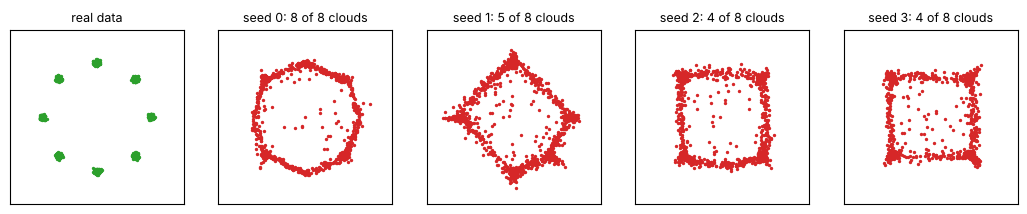

In [8]:
panels = [(f"seed {s}: {final[s][0]} of 8 clouds", ring_runs[s][6000]) for s in range(4)]      # the first four seeds, no selection
fig = gn.plot_ring(panels, real_ring)
save_figure(fig, "02_ring_mode_collapse.png")
plt.show()

**What to notice.** The answer to our prediction is **no**: all eight clouds were reached in only **2 of 8 seeds** (8, 5, 4, 4, 4, 6, 8, 7 clouds; on average 5.75).
The figure shows the first four seeds, chosen by the seed number and not by the result.

- **Mode dropping:** in six of the eight seeds the forger leaves one to four clouds uncovered. In seeds 2 and 3 the points form a square that touches only four clouds.
- **Smoothing between the modes:** the generated points do not sit in small clouds; they form a *continuous curve* that connects the places they reach, so between 22% and 38% of the points are far (more than 0.3) from every real cloud (the share of "good" points is only 0.62 to 0.78). A smooth generator finds it hard to jump from one cloud to the next without passing through the gap.

*Figure: the real data (green) and the points made by the generator after 6,000 steps for seeds 0 to 3 (red).*

## 7 · Instability: the number of covered clouds over time

If training were stable, the number of covered clouds would climb and stay. We measure it at 13 moments for each seed.

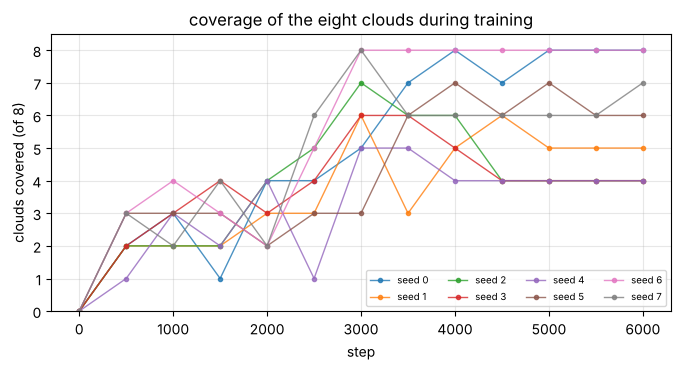

in 20 of 88 consecutive pairs of measurements (after step 500) the number of covered clouds went DOWN
coverage at steps 3000 / 4500 / 6000 for seed 2: [7, 4, 4]


In [9]:
timeline = {seed: [gn.modes_covered(ring_runs[seed][k])[0] for k in ring_moments] for seed in range(8)}

fig, ax = plt.subplots(figsize=(8, 3.6))
for seed, values in timeline.items():
    ax.plot(ring_moments, values, "o-", ms=3, lw=1, alpha=.8, label=f"seed {seed}")
ax.set_xlabel("step"); ax.set_ylabel("clouds covered (of 8)"); ax.set_ylim(0, 8.5); ax.grid(alpha=.3)
ax.legend(ncol=4, fontsize=7); ax.set_title("coverage of the eight clouds during training")
save_figure(fig, "02_ring_instability.png")
plt.show()

drops = sum(int(b < a) for values in timeline.values() for a, b in zip(values[1:], values[2:]))
pairs = sum(len(values) - 2 for values in timeline.values())
print(f"in {drops} of {pairs} consecutive pairs of measurements (after step 500) the number of covered clouds went DOWN")
print("coverage at steps 3000 / 4500 / 6000 for seed 2:", [timeline[2][ring_moments.index(k)] for k in (3000, 4500, 6000)])

**What to notice.**

- Coverage rises during the first 3,000 to 4,000 steps but **not steadily**: in 20 of the 88 consecutive pairs of measurements (after step 500) the number of covered clouds went down.
- **Several seeds peaked and then fell back.** Seed 7 had all 8 clouds at step 3,000 and ended with 7 after dropping to 6; seed 2 peaked at 7 around step 3,000 and ended at 4 (7, 4 and 4 clouds at steps 3,000, 4,500 and 6,000). Seeds 0 and 6 reached all 8; seed 0 even dipped to 7 at step 4,500 and recovered.
- So the result at the end of training depends on luck, and a snapshot taken at a random moment can look better or worse than the final state. This is what we mean by **instability**: the game does not settle on its own.

*Figure: number of clouds covered (of 8) every 500 steps for each of the eight seeds.*

### Check yourself

1. Why does the ring toy make mode collapse easier to see than the digits?
2. Name one reason why a generator might cover fewer modes later in training than earlier.

<details>
<summary>Answers</summary>


1. We know exactly where the modes are (eight known centres), so we can count them without a judge or a classifier.
2. The detective adapts to what the forger shows him: when he learns that one cloud's points are fake, the forger is pushed away from it, and he may move towards another cloud and leave the first one uncovered (whack-a-mole).

</details>

## 8 · What can be done? (names only, not tested here)

People have proposed many fixes; we did not test any of them in this repository, so treat the list as a map for further reading:

- change the *loss* (for example the Wasserstein GAN of Arjovsky, Chintala and Bottou, 2017);
- balance the two networks (different learning rates, several detective steps per forger step);
- help the detective see whole batches, so that a lack of variety is visible to him (minibatch discrimination, Salimans et al., 2016);
- add labels (conditional GANs), so that we can ask for each digit.

## 9 · Common mistakes

- **Reading the loss like a classifier's loss.** A flat loss can mean a draw, a weak detective or a loophole.
- **Judging by a handful of pictures.** A GAN can make beautiful pictures of two digits and nothing else; count the variety.
- **Believing one seed.** In the ring game the number of covered clouds changed from seed to seed: one run is an anecdote.
- **Trusting the ruler blindly.** A classifier measures recognisability, not realism.

## 10 · Recap

- Follow a GAN with samples from *fixed noise*, loss curves *and* a measuring device; any single one of them can mislead.
- Mode collapse (too little variety) and instability (coverage that goes up and down) are real and are easy to see on a toy where the modes are known.
- Results depend on the seed; report several, and say what you did not test.

**Next:** this was the last notebook. The README collects the whole path and the honest results.